<a href="https://colab.research.google.com/github/Juna1013/bert-prac/blob/main/bert_prac.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers fugashi unidic-lite

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# 環境設定
import torch, transformers

print("transformers:", transformers.__version__)
print("GPU avaliable:", torch.cuda.is_available())

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

transformers: 5.22.1
GPU avaliable: True
NVIDIA A100-SXM4-40GB


In [ ]:
# トークナイザで文章を数字にする
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("bert-base-uncased")
print("語彙サイズ:", tok.vocab_size)

text = "Natural language processing is unbelievably fascinating."
tokens = tok.tokenize(text)
ids = tok.tokenize(text)
print("tokens:", tokens)
print("ids   :", ids)

# モデルに実際に渡される形
enc = tok(text)
print("\n入力ID列:", enc["input_ids"])
print("復元（special付き）:", tok.convert_ids_to_tokens(enc["input_ids"]))

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

語彙サイズ: 30522
tokens: ['natural', 'language', 'processing', 'is', 'un', '##bel', '##ie', '##va', '##bly', 'fascinating', '.']
ids   : ['natural', 'language', 'processing', 'is', 'un', '##bel', '##ie', '##va', '##bly', 'fascinating', '.']

入力ID列: [101, 3019, 2653, 6364, 2003, 4895, 8671, 2666, 3567, 6321, 17160, 1012, 102]
復元（special付き）: ['[CLS]', 'natural', 'language', 'processing', 'is', 'un', '##bel', '##ie', '##va', '##bly', 'fascinating', '.', '[SEP]']


In [ ]:
# 穴埋めで文脈理解を確認する
import pandas as pd
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
fill = pipeline("fill-mask", model="bert-base-uncased", device=device)

def show(sentence, k=5):
  res = fill(sentence, top_k=k)
  df = pd.DataFrame([{"token": r["token_str"], "score": round(r["score"], 4)} for r in res])
  print(sentence)
  display(df)

show("The capital of France is [MASK].")
show("I went to the [MASK] to buy some bread.")
show("She is a [MASK] who treats patients at the hospital.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


The capital of France is [MASK].


,token,score
0,paris,0.4168
1,lille,0.0714
2,lyon,0.0634
3,marseille,0.0444
4,tours,0.0303


I went to the [MASK] to buy some bread.


,token,score
0,market,0.7800
1,store,0.0561
2,bakery,0.0467
3,kitchen,0.0228
4,markets,0.0151


She is a [MASK] who treats patients at the hospital.


,token,score
0,nurse,0.7514
1,doctor,0.1759
2,physician,0.0139
3,patient,0.0117
4,psychiatrist,0.0088


In [ ]:
# 文脈が変わると予測が変わるか確認する
show("He deposited the check at the [MASK].")
show("He caught a big fish from the [MASK].")

He deposited the check at the [MASK].


,token,score
0,table,0.3640
1,counter,0.1810
2,desk,0.1527
3,bank,0.0456
4,door,0.0351


He caught a big fish from the [MASK].


,token,score
0,river,0.0912
1,lake,0.0891
2,water,0.0872
3,pond,0.0792
4,sea,0.0526


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


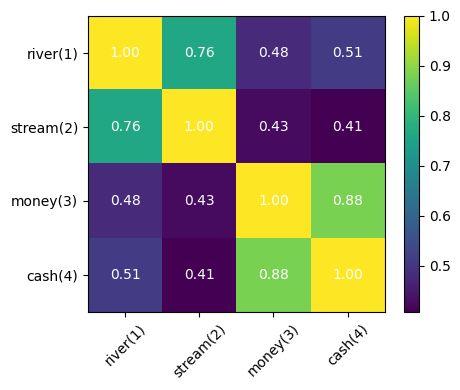

In [ ]:
# 文脈依存の単語を埋め込む
import numpy as np
import matplotlib.pyplot as plt
from transformers import AutoModel

model = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True)
model.eval()
dev = "cuda" if torch.cuda.is_available() else "cpu"
model.to(dev)

def embed(sentence, target):
  enc = tok(sentence, return_tensors="pt").to(dev)
  with torch.no_grad():
    out = model(**enc)
  toks = tok.convert_ids_to_tokens(enc["input_ids"][0])
  idx = toks.index(target)
  return out.last_hidden_state[0, idx].cpu().numpy()

sents = [
    "I sat on the river bank and watched the water.",
    "He grew up on the bank of a quiet stream.",
    "I deposited money at the bank this morning.",
    "She withdrew cash from the bank.",
]
vecs = np.stack([embed(s, "bank") for s in sents])

# コサイン類似度を求める
v = vecs / np.linalg.norm(vecs, axis=1, keepdims=True)
sim = v @ v.T

labels = ["river(1)", "stream(2)", "money(3)", "cash(4)"]
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(sim, cmap="viridis", vmin=sim.min(), vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(labels, rotation=45)
ax.set_yticks(range(4)); ax.set_yticklabels(labels)

for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", color="w")

plt.colorbar(im)
plt.tight_layout()
plt.show()

層数: 12 ヘッド数: 12


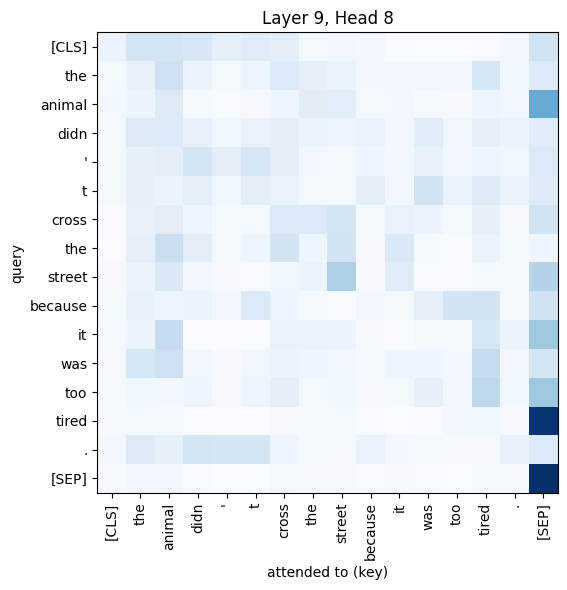

In [ ]:
# Attentionの可視化
sentence = "The animal didn't cross the street because it was too tired."
enc = tok(sentence, return_tensors="pt").to(dev)
with torch.no_grad():
    out = model(**enc)
toks = tok.convert_ids_to_tokens(enc["input_ids"][0])

def plot_attn(layer, head):
    a = out.attentions[layer][0, head].cpu().numpy()
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.imshow(a, cmap="Blues")
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90)
    ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks)
    ax.set_xlabel("attended to (key)"); ax.set_ylabel("query")
    ax.set_title(f"Layer {layer+1}, Head {head+1}")
    plt.tight_layout(); plt.show()

print("層数:", len(out.attentions), "ヘッド数:", out.attentions[0].shape[1])
plot_attn(layer=8, head=7)

In [ ]:
# "it"が何を見ているかを全層・全ヘッドで平均して確認
it_idx = toks.index("it")
avg = torch.stack(out.attentions).mean(dim=(0, 2))[0, it_idx].cpu().numpy()
pd.DataFrame({"token": toks, "attention from 'it'": avg.round(3)}).sort_values("attention from 'it'", ascending=False).head(6)

,token,attention from 'it'
15,[SEP],0.247
0,[CLS],0.097
2,animal,0.091
14,.,0.081
9,because,0.075
13,tired,0.063


In [ ]:
# 日本語でも試す
ja_name = "tohoku-nlp/bert-base-japanese-v3"
ja_tok = AutoTokenizer.from_pretrained(ja_name)
print(ja_tok.tokenize("自然言語処理はとても面白い分野です。"))

ja_fill = pipeline("fill-mask", model=ja_name, device=device)

def show_ja(sentence, k=5):
    res = ja_fill(sentence, top_k=k)
    print(sentence)
    df = pd.DataFrame([{"token": r["token_str"], "score": round(r["score"], 4)} for r in res])
    display(df)

show_ja("日本の首都は[MASK]です。")
show_ja("私は毎朝コーヒーを[MASK]。")
show_ja("明日は雨が降るので[MASK]を持っていく。")

config.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/251 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/231k [00:00<?, ?B/s]

['自然', '言語', '処理', 'は', 'とても', '面白い', '分野', 'です', '。']


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  447MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (6 outputs left out)

私は毎朝コーヒーを[MASK]。


,token,score
0,飲む,0.6525
1,頼む,0.1160
2,出す,0.0328
3,入れる,0.0326
4,食べる,0.0147


明日は雨が降るので[MASK]を持っていく。


,token,score
0,それ,0.0601
1,水,0.0505
2,荷物,0.0457
3,傘,0.0446
4,これ,0.0356
